# Miniproject Pengolahan Citra Ijazah

Notebook untuk memproses 9 gambar ijazah: orientasi, grayscale, CLAHE, ROI nomor dan tanda tangan, OCR, thresholding, morphology, CER, serta tabel hasil.

**Penting:** periksa orientasi dan ROI secara visual sebelum memakai hasil. Deteksi tanda tangan berbasis foreground adalah baseline sederhana, bukan pengenal tanda tangan terlatih. CER hanya valid jika nomor acuan benar.

## 1. Instalasi

In [1]:
!apt-get -qq update && apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract opencv-python-headless pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 2. Temukan 9 gambar
Jika `gambar_files` sudah ada dari sesi sebelumnya, akan digunakan. Jika tidak, ubah `DATA_DIR` ke folder sebenarnya.

In [3]:
import os, re, glob, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, pytesseract
from IPython.display import display

# Gunakan variabel gambar_files bila sudah tersedia dari sesi sebelumnya.
# Jika notebook dibuka pada runtime baru, cari file gambar di lokasi yang tersedia.
DATA_DIR = "/content"  # boleh diganti dengan folder gambar yang diketahui
EXTS = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff")

if "gambar_files" in globals() and len(gambar_files) > 0:
    image_paths = list(gambar_files)
else:
    image_paths = []
    for ext in EXTS:
        image_paths.extend(glob.glob(os.path.join(DATA_DIR, "**", ext), recursive=True))

# Jika belum ditemukan, cari nama 9 file yang digunakan pada miniproject.
keywords = [
    "01_HighQuality", "02_LowContrast", "03_Blurred",
    "04_HighNoise", "05_LowResolution", "06_Faded",
    "07_ColorShift", "08_JPEGCompression", "09_CombinedDegradation"
]

def find_image_paths():
    found = {}
    skip_dirs = {"proc", "sys", "dev", "usr", "opt", "lib", "lib64", "var"}
    for root, dirs, files in os.walk("/"):
        dirs[:] = [d for d in dirs if d not in skip_dirs and not d.startswith(".")]
        for filename in files:
            low = filename.lower()
            for key in keywords:
                if low.startswith(key.lower()) and key not in found:
                    found[key] = os.path.join(root, filename)
        if len(found) == len(keywords):
            break
    return [found[k] for k in keywords if k in found]

if not image_paths:
    image_paths = find_image_paths()

# Urutkan sesuai nama variasi jika semua 9 variasi berhasil ditemukan.
matched = [
    next((p for p in image_paths if os.path.basename(p).lower().startswith(k.lower())), None)
    for k in keywords
]
if all(matched):
    image_paths = matched
else:
    image_paths = sorted(set(image_paths))

print("Jumlah gambar:", len(image_paths))
for p in image_paths:
    print("-", os.path.basename(p), "->", p)

if not image_paths:
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Pastikan gambar tersedia pada runtime Colab, "
        "atau atur DATA_DIR ke folder yang benar."
    )
if len(image_paths) != 9:
    print("PERINGATAN: tugas membutuhkan 9 gambar; yang ditemukan:", len(image_paths))


Jumlah gambar: 9
- 01_HighQuality_Enhanced (1).jpg -> /content/01_HighQuality_Enhanced (1).jpg
- 02_LowContrast (1).jpg -> /content/02_LowContrast (1).jpg
- 03_Blurred (1).jpg -> /content/03_Blurred (1).jpg
- 04_HighNoise (1).jpg -> /content/04_HighNoise (1).jpg
- 05_LowResolution_Upsampled (1).jpg -> /content/05_LowResolution_Upsampled (1).jpg
- 06_Faded_Underexposed (1).jpg -> /content/06_Faded_Underexposed (1).jpg
- 07_ColorShift_WarmTint (1).jpg -> /content/07_ColorShift_WarmTint (1).jpg
- 08_JPEGCompression_Artifacts (1).jpg -> /content/08_JPEGCompression_Artifacts (1).jpg
- 09_CombinedDegradation (1).jpg -> /content/09_CombinedDegradation (1).jpg


## 3. Pilih orientasi yang benar
Lihat empat pratinjau, lalu atur `ROTATION_DEGREES` ke orientasi yang membuat teks terbaca normal.

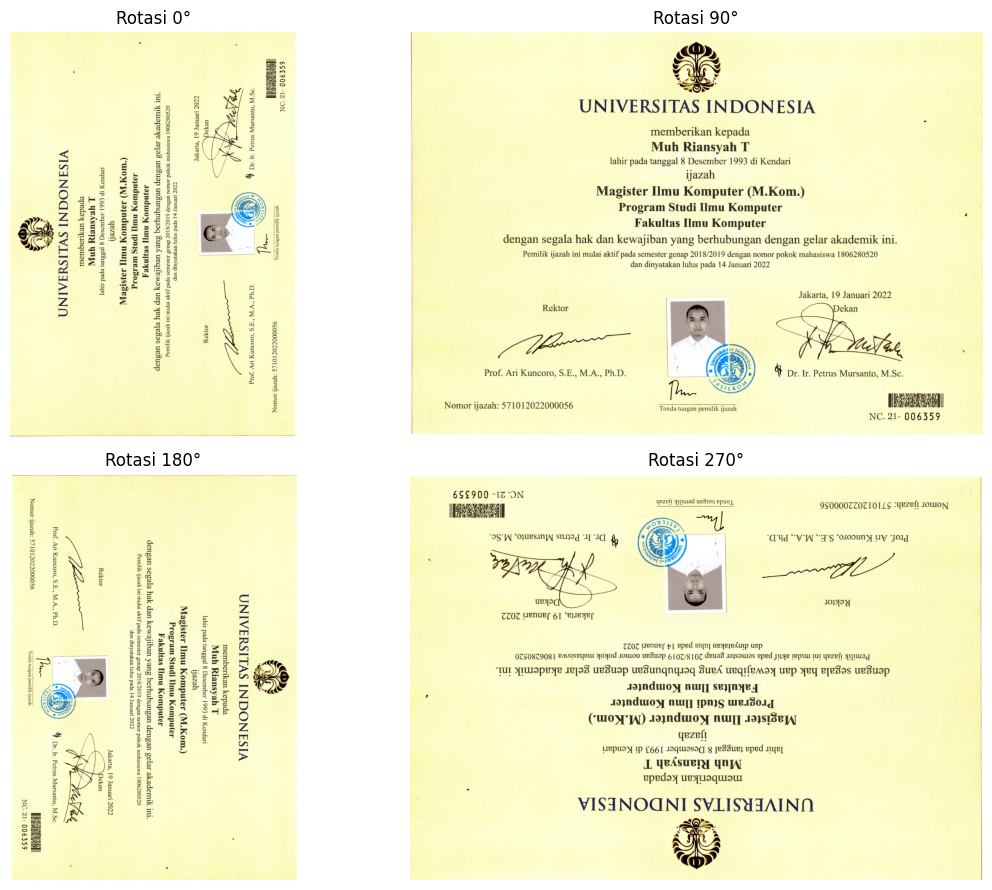

In [14]:
def rotate_image(img, angle):
    if angle == 0: return img.copy()
    if angle == 90: return cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    if angle == 180: return cv2.rotate(img, cv2.ROTATE_180)
    if angle == 270: return cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
    raise ValueError('Gunakan 0, 90, 180, atau 270.')

img0 = cv2.imread(image_paths[0])
if img0 is None: raise ValueError('Gagal membaca gambar pertama.')
fig, ax = plt.subplots(2,2,figsize=(12,9))
for a, deg in zip(ax.flat,[0,90,180,270]):
    a.imshow(cv2.cvtColor(rotate_image(img0,deg),cv2.COLOR_BGR2RGB)); a.set_title(f'Rotasi {deg}°'); a.axis('off')
plt.tight_layout(); plt.show()
ROTATION_DEGREES = 90  # UBAH setelah memeriksa pratinjau

## 4. Atur dan periksa ROI
ROI format proporsi `(x1,y1,x2,y2)` bernilai 0–1. Isi koordinat berdasarkan gambar setelah rotasi. Jangan lanjutkan jika crop tidak mencakup nomor/tanda tangan secara utuh.

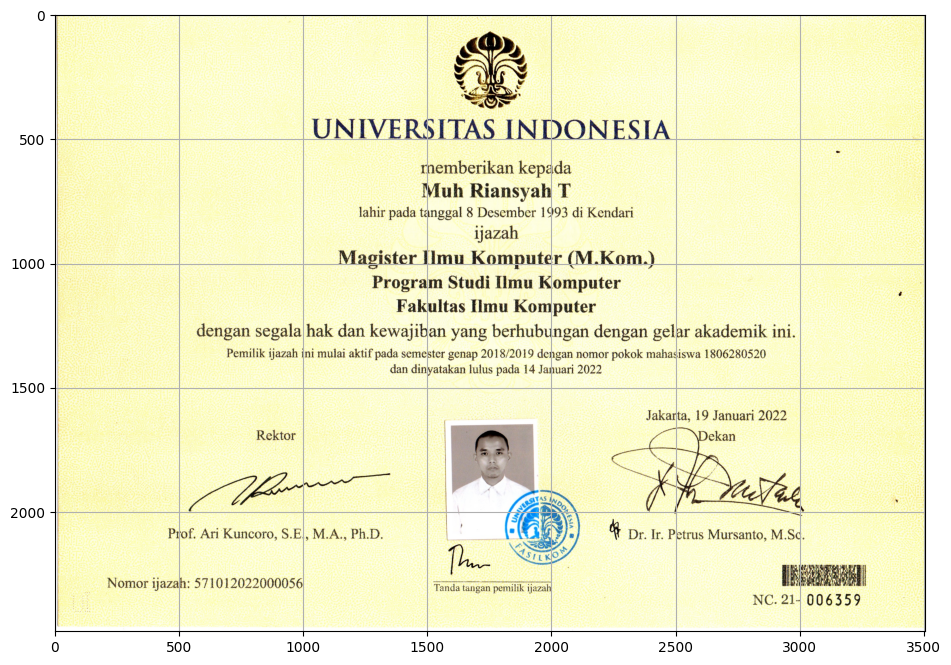

Tinggi, lebar: 2481 3506


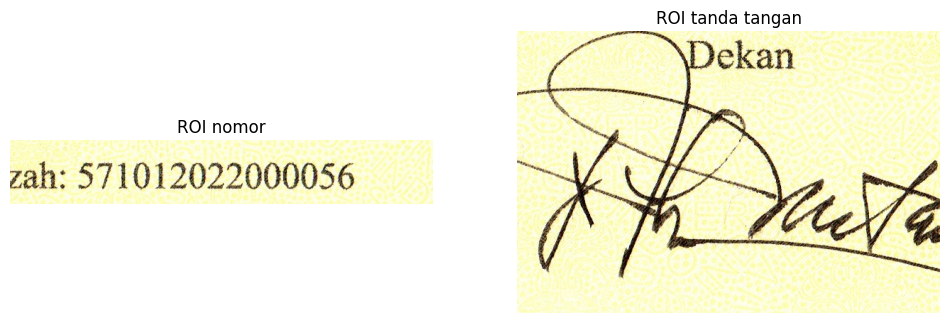

In [25]:

ROI_NUMBER = (0.13, 0.90, 0.32, 0.94)
ROI_SIGNATURE = (0.67, 0.67, 0.84, 0.83)

def crop_relative(img, roi):
    if roi is None: return None
    h,w=img.shape[:2]; x1,y1,x2,y2=roi
    xa,xb=max(0,int(x1*w)),min(w,int(x2*w)); ya,yb=max(0,int(y1*h)),min(h,int(y2*h))
    if xb<=xa or yb<=ya: raise ValueError('Koordinat ROI tidak valid.')
    return img[ya:yb,xa:xb].copy()

preview=rotate_image(img0,ROTATION_DEGREES); h,w=preview.shape[:2]
plt.figure(figsize=(12,8)); plt.imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB)); plt.xlim(0,w); plt.ylim(h,0); plt.grid(True); plt.show()
print('Tinggi, lebar:',h,w)
if ROI_NUMBER is not None and ROI_SIGNATURE is not None:
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].imshow(cv2.cvtColor(crop_relative(preview,ROI_NUMBER),cv2.COLOR_BGR2RGB)); ax[0].set_title('ROI nomor'); ax[0].axis('off')
    ax[1].imshow(cv2.cvtColor(crop_relative(preview,ROI_SIGNATURE),cv2.COLOR_BGR2RGB)); ax[1].set_title('ROI tanda tangan'); ax[1].axis('off'); plt.show()
else: print('Isi ROI_NUMBER dan ROI_SIGNATURE, lalu jalankan ulang sel ini untuk memeriksa hasil crop.')

## 5. Nomor acuan, metode, dan CER
Isi `REFERENCE_NUMBER` dengan nomor ijazah yang benar-benar tercetak pada dokumen. Jika kosong, CER tidak dapat digunakan untuk menentukan metode terbaik.

In [22]:
REFERENCE_NUMBER = '571012022000056'
OCR_CONFIG = '--oem 3 --psm 7'

def gray(img): return cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) if img.ndim==3 else img.copy()
def enhance(img):
    g=gray(img); clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(g)
    den=cv2.fastNlMeansDenoising(clahe,None,10,7,21); blur=cv2.GaussianBlur(den,(0,0),1.2); sharp=cv2.addWeighted(den,1.5,blur,-0.5,0)
    glob=cv2.threshold(clahe,127,255,cv2.THRESH_BINARY)[1]
    otsu=cv2.threshold(clahe,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)[1]
    adap=cv2.adaptiveThreshold(clahe,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,10)
    k=np.ones((3,3),np.uint8); opening=cv2.morphologyEx(otsu,cv2.MORPH_OPEN,k); closing=cv2.morphologyEx(otsu,cv2.MORPH_CLOSE,k)
    return {'grayscale':g,'clahe':clahe,'clahe_denoise_sharpen':sharp,'global_threshold':glob,'otsu_threshold':otsu,'adaptive_threshold':adap,'opening':opening,'closing':closing}

def clean(s): return re.sub(r'[^A-Z0-9]','',str(s).upper())
def lev(a,b):
    if len(a)<len(b): a,b=b,a
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]
        for j,cb in enumerate(b,1): cur.append(min(cur[-1]+1,prev[j]+1,prev[j-1]+(ca!=cb)))
        prev=cur
    return prev[-1]
def cer(ref,pred):
    ref,pred=clean(ref),clean(pred)
    return np.nan if not ref else lev(ref,pred)/len(ref)
def ocr(img): return pytesseract.image_to_string(img,config=OCR_CONFIG+' -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789-/').strip()

## 6. Pipeline untuk semua gambar

In [26]:
if ROI_NUMBER is None or ROI_SIGNATURE is None:
    raise ValueError('Isi dan periksa ROI_NUMBER serta ROI_SIGNATURE terlebih dahulu.')
rows=[]; examples=[]; SIGNATURE_THRESHOLD=0.01
for path in image_paths:
    raw=cv2.imread(path)
    if raw is None: print('Lewati file:',path); continue
    oriented=rotate_image(raw,ROTATION_DEGREES)
    nr=crop_relative(oriented,ROI_NUMBER); sr=crop_relative(oriented,ROI_SIGNATURE)
    methods=enhance(nr)
    names=['grayscale','clahe','clahe_denoise_sharpen','global_threshold','otsu_threshold','adaptive_threshold']
    texts = {
    name: ''.join(c for c in ocr(methods[name]).upper() if c.isdigit())
    for name in names
}
    sg=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(gray(sr))
    binary=cv2.threshold(sg,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)[1]
    k=np.ones((3,3),np.uint8); morph=cv2.morphologyEx(cv2.morphologyEx(binary,cv2.MORPH_OPEN,k),cv2.MORPH_CLOSE,k)
    fg=int(np.count_nonzero(morph)); ratio=fg/morph.size if morph.size else 0
    row={'file':os.path.basename(path),'rotation_degrees':ROTATION_DEGREES,'nomor_ocr':texts['clahe'],'signature_status':'PRESENT' if ratio>=SIGNATURE_THRESHOLD else 'ABSENT','foreground_pixels':fg,'foreground_ratio':round(ratio,5)}
    row.update({'OCR_'+k:v for k,v in texts.items()}); row.update({'CER_'+k:cer(REFERENCE_NUMBER,v) for k,v in texts.items()}); rows.append(row)
    if len(examples)<3: examples.append((os.path.basename(path),nr,sr,methods,morph))
df_results=pd.DataFrame(rows)
print('Gambar berhasil diproses:',len(df_results)); display(df_results)

Gambar berhasil diproses: 9


,file,rotation_degrees,nomor_ocr,signature_status,foreground_pixels,foreground_ratio,OCR_grayscale,OCR_clahe,OCR_clahe_denoise_sharpen,OCR_global_threshold,OCR_otsu_threshold,OCR_adaptive_threshold,CER_grayscale,CER_clahe,CER_clahe_denoise_sharpen,CER_global_threshold,CER_otsu_threshold,CER_adaptive_threshold
0,01_HighQuality_Enhanced (1).jpg,90,571012022000056,PRESENT,23785,0.10052,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,,0.0,0.0,0.0,0.000000,0.0,1.0
1,02_LowContrast (1).jpg,90,571012022000056,PRESENT,23589,0.09969,571012022000056,571012022000056,571012022000056,7112022000656,571012022000056,571012022000056,0.0,0.0,0.0,0.200000,0.0,0.0
2,03_Blurred (1).jpg,90,571012022000056,PRESENT,38660,0.16339,571012022000056,571012022000056,571012022000056,571012022000086,571012022000056,571012022000056,0.0,0.0,0.0,0.066667,0.0,0.0
3,04_HighNoise (1).jpg,90,571012022000056,PRESENT,26159,0.11056,571012022000056,571012022000056,,571012022000056,571012022000056,571012022000056,0.0,0.0,1.0,0.000000,0.0,0.0
4,05_LowResolution_Upsampled (1).jpg,90,571012022000056,PRESENT,28403,0.12004,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,0.0,0.0,0.0,0.000000,0.0,0.0
5,06_Faded_Underexposed (1).jpg,90,571012022000056,PRESENT,22355,0.09448,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,0.0,0.0,0.0,0.000000,0.0,0.0
6,07_ColorShift_WarmTint (1).jpg,90,571012022000056,PRESENT,24124,0.10196,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,,0.0,0.0,0.0,0.000000,0.0,1.0
7,08_JPEGCompression_Artifacts (1).jpg,90,571012022000056,PRESENT,24765,0.10467,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,,0.0,0.0,0.0,0.000000,0.0,1.0
8,09_CombinedDegradation (1).jpg,90,571012022000056,PRESENT,26057,0.11013,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,571012022000056,0.0,0.0,0.0,0.000000,0.0,0.0


## 7. Bandingkan CER dan visualisasikan

,mean_CER
CER_grayscale,0.000000
CER_clahe,0.000000
CER_otsu_threshold,0.000000
CER_global_threshold,0.029630
CER_clahe_denoise_sharpen,0.111111
CER_adaptive_threshold,0.333333


Metode CER terendah: grayscale | CER rata-rata: 0.0


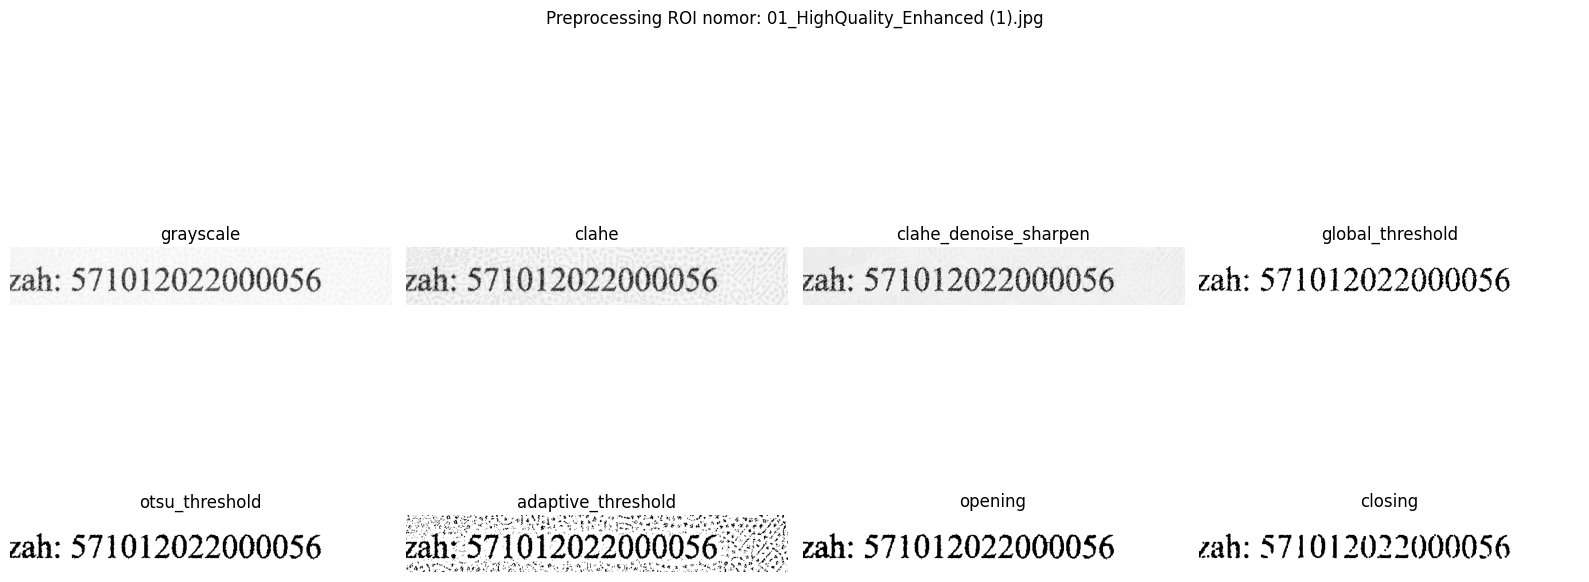

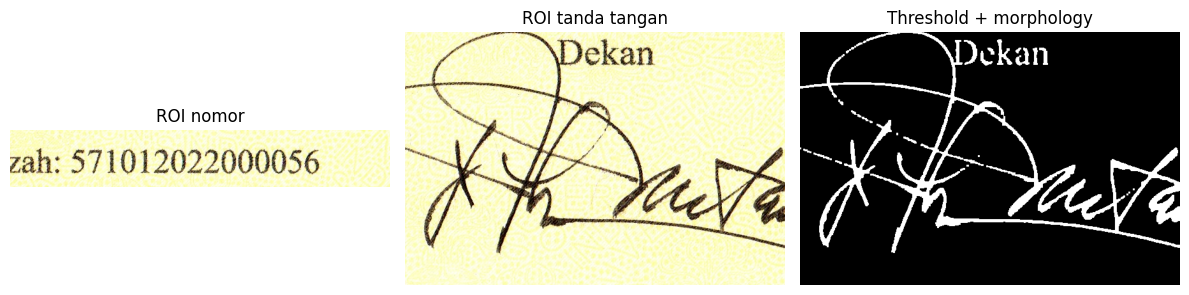

In [27]:
cer_cols=[c for c in df_results.columns if c.startswith('CER_')]
if REFERENCE_NUMBER.strip():
    mean_cer=df_results[cer_cols].mean(numeric_only=True).sort_values()
    display(mean_cer.rename('mean_CER').to_frame())
    if mean_cer.notna().any(): print('Metode CER terendah:',mean_cer.dropna().idxmin().replace('CER_',''),'| CER rata-rata:',round(float(mean_cer.dropna().min()),4))
    else: print('CER tidak tersedia; periksa nomor acuan dan OCR.')
else: print('Isi REFERENCE_NUMBER yang benar untuk membandingkan CER.')

if examples:
    name,nr,sr,methods,morph=examples[0]
    keys=['grayscale','clahe','clahe_denoise_sharpen','global_threshold','otsu_threshold','adaptive_threshold','opening','closing']
    fig,ax=plt.subplots(2,4,figsize=(16,8))
    for a,k in zip(ax.flat,keys): a.imshow(methods[k],cmap='gray'); a.set_title(k); a.axis('off')
    plt.suptitle('Preprocessing ROI nomor: '+name); plt.tight_layout(); plt.show()
    fig,ax=plt.subplots(1,3,figsize=(12,4)); ax[0].imshow(cv2.cvtColor(nr,cv2.COLOR_BGR2RGB)); ax[0].set_title('ROI nomor'); ax[1].imshow(cv2.cvtColor(sr,cv2.COLOR_BGR2RGB)); ax[1].set_title('ROI tanda tangan'); ax[2].imshow(morph,cmap='gray'); ax[2].set_title('Threshold + morphology')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

## 8. Output verifikasi dan ekspor CSV

`PRESENT/ABSENT` merupakan indikasi sederhana berdasarkan rasio foreground; uji terhadap label manual sebelum mengklaim akurasi.

In [13]:
for _,r in df_results.iterrows():
    print('\nInput:',r['file']); print('Nomor Ijazah:',r['nomor_ocr'] or '(OCR tidak menemukan teks)'); print('Tanda Tangan:',r['signature_status'])
csv_path='hasil_miniproject_ijazah.csv'; df_results.to_csv(csv_path,index=False,encoding='utf-8-sig'); print('\nCSV tersimpan:',csv_path)
try:
    from google.colab import files
    files.download(csv_path)
except Exception: pass


Input: 01_HighQuality_Enhanced (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 02_LowContrast (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 03_Blurred (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 04_HighNoise (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 05_LowResolution_Upsampled (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 06_Faded_Underexposed (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 07_ColorShift_WarmTint (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 08_JPEGCompression_Artifacts (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

Input: 09_CombinedDegradation (1).jpg
Nomor Ijazah: (OCR tidak menemukan teks)
Tanda Tangan: PRESENT

CSV tersimpan: hasil_miniproject_ijazah.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Penjelasan metode untuk laporan

- **Grayscale:** mengubah citra menjadi intensitas abu-abu agar analisis lebih sederhana.
- **CLAHE:** meningkatkan kontras lokal.
- **Denoising dan sharpening:** mengurangi sebagian noise dan mempertegas tepi karakter.
- **Global threshold:** memakai satu ambang intensitas untuk seluruh citra.
- **Otsu:** memilih ambang berdasarkan histogram intensitas.
- **Adaptive threshold:** menghitung ambang lokal untuk mengatasi pencahayaan tidak merata.
- **Opening:** mengurangi komponen kecil; **closing:** membantu menyambungkan celah kecil.
- **OCR:** Tesseract membaca karakter pada ROI nomor.
- **CER:** jarak edit karakter dibagi jumlah karakter referensi; makin rendah makin baik.
- **Deteksi tanda tangan:** rasio foreground pada ROI setelah threshold dan morphology. Ini baseline sederhana, bukan model terlatih; cap/noda dapat menghasilkan false positive.

Kesimpulan enhancement harus berdasarkan CER rata-rata yang terukur dengan nomor acuan yang benar dan ROI valid. Jangan menyatakan metode terbaik jika CER belum dapat dihitung.